# Домашнее задание 1

__Дедлайн: 17.11.2021, 23:59__

Файлы должны иметь имя HW1_ФАМИЛИЯ.ipynb, где ФАМИЛИЯ - Ваша фамилия русскими буквами.

Решение каждой задачи необходимо поместить после её условия.

Пожалуйста, пишите свои решения чётко и понятно.
При полном запуске Вашего решения (Kernel -> Restart & Run All) все ячейки должны выполняться **без ошибок**.

**Во всех задачах, где требуется сравнить методы, требуется аккуратное офрмление графиков, если Вы их будете строить, и комментарии к графикам (кто кого быстрее и когда сходится, какие интересные моменты Вы видите на графиках, как Вы их можете объяснить). Аналогично, требуются комментарии в случае, если Вы сравниваете время работы.**

Задачи со звездочкой не являются обязательными к решению, но за них будут даны бонусные баллы.

Суммарное количество баллов: 36

## Задача 1. Линейная регрессия [15]

Рассмотрим задачу линейной регресии с $\ell_2$ регуляризатором:

$$\min_{w\in\mathbb{R}^n} \|Xw-y\|^2 + \frac{\lambda}{2}\|w\|^2,$$
где $X\in\mathbb{R}^{m\times n}, y\in\mathbb{R}^m, \lambda \in \mathbb{R}_+$ - параметры задачи. Таргеты $y$ берутся из файлов `data/task1/y*.npy` с соответсвующим именем. $X$ из файла `data/task1/X.npy`. Коэффициент $\lambda$ во всех случаях возьмем равным $10^{-1}$.

Задача оптимизации, возникающая при линейной регрессии, является оптимальным

1. [3] Реализуйте Адаптивный (универсальный) градиентный спуск (без критерия остановки) (см. Лекция 3)

2. [3] Реализуйте Метод подобных треугольников

3. [5] Опробуйте различные значения неизвестных параметров в следующих методах и выберите лучшие значения

    * Метод градиентного спуска

    * Метод подобных треугольников

    * Метод тяжелого шарика

    Оформляйте исследование для каждого метода проводить отдельно. Подумайте, как полученные значения параметров соотносятся с теорией.

4. [4] Сравните методы из предыдущего пункта и метод сопряженных градиентов на данной задаче

### Решение задачи 1:

In [52]:
import numpy as np
from time import time
from tqdm import tqdm
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar


class LinearRegression:
    def __init__(self, X_path, y_path, lambda_reg=0.1):
        self.X = np.load(X_path)
        self.y = np.load(y_path)
        self.lambda_reg = lambda_reg
        self.m, self.n = self.X.shape
        self.histories = {}

    def reset_history(self):
        self.history = {
            'iterations': [],
            'grad_norm': [],
            'times': []
        }

    def save_iteration_results(self, iteration, grad, elapsed_time):
        grad_norm = np.linalg.norm(grad) ** 2
        self.history['iterations'].append(iteration)
        self.history['grad_norm'].append(grad_norm)
        self.history['times'].append(elapsed_time)       

    def loss_function(self, w):
        return 1 / self.m * np.linalg.norm(self.X @ w - self.y) ** 2 + (self.lambda_reg / 2) * np.linalg.norm(w) ** 2

    def loss_gradient(self, w):
        return 1 / self.m * self.X.T @ (self.X @ w - self.y) + self.lambda_reg * w

    def adaptive_gradient_descent(self, w_0, L_0, num_iter):
        self.reset_history()
        w = w_0.copy()
        L = L_0
        grad = self.loss_gradient(w)
        loss = self.loss_function(w)

        start_time = time()
        for i in tqdm(range(num_iter), desc='Adaptive Gradient Descent'):
            w_prev = w.copy()
            w -= 1 / L * grad

            loss_prev = loss
            loss = self.loss_function(w)
            grad_prev = grad.copy()
            grad = self.loss_gradient(w)
            self.save_iteration_results(i + 1, grad, time() - start_time)

            if (loss <= loss_prev + grad_prev.T @ (w - w_prev) + L / 2 * np.linalg.norm(w - w_prev) ** 2):
                L /= 2
            else:
                L *= 2

        self.histories['Adaptive Gradient Descent'] = self.history

    def triangular_method(self, w_0, alpha_0, A_0, L, num_iter):
        self.reset_history()
        w = w_0.copy()
        u = w_0.copy()
        v = w_0.copy()
        alpha = alpha_0
        A = A_0
        grad = self.loss_gradient(w)

        start_time = time()
        for i in tqdm(range(num_iter), desc='Triangular Method'):
            alpha = (1 + np.sqrt(1 + 4 * A * L)) / (2 * L)
            A_prev = A
            A += alpha

            v = (alpha * u + A_prev * w) / A
            grad_v = self.loss_gradient(v)
            u -= alpha * grad_v
            w = 1 / A * (alpha * u + A_prev * w)

            grad = self.loss_gradient(w)
            self.save_iteration_results(i + 1, grad, time() - start_time)

        self.histories['Triangular Method'] = self.history

    def heavy_ball_method(self, w_0, beta, L, num_iter):
        self.reset_history()
        w = w_0.copy()
        w_prev = np.zeros_like(w)
        grad = self.loss_gradient(w)

        start_time = time()
        for i in tqdm(range(num_iter), desc='Heavy Ball Method'):
            w_prev2 = w_prev.copy()
            w_prev = w.copy()
            w = w - 1 / L * grad + beta * (w_prev - w_prev2)

            grad = self.loss_gradient(w)
            self.save_iteration_results(i + 1, grad, time() - start_time)

        self.histories['Heavy Ball Method'] = self.history

    def conjugate_gradients_method(self, w_0, L, num_iter):
        self.reset_history()
        w = w_0.copy()
        w_prev = np.zeros_like(w)
     
        start_time = time()
        for i in tqdm(range(num_iter), desc="Conjugate Gradients Method"):
            w_prev2 = w_prev.copy()
            w_prev = w.copy()
            grad = self.loss_gradient(w)
            norm_grad = np.linalg.norm(grad) ** 2
            p = w_prev - w_prev2
            A = self.X.T @ self.X
            pp = np.dot((A @ p), p)
            gp = np.dot((A @ grad), p)
            gg = np.dot((A @ grad), grad)
            beta = (norm_grad * pp - np.dot(grad, p) * gg) / (gg * pp - gp ** 2)

            w = w - 1 / L * grad + beta * p

            grad = self.loss_gradient(w)
            self.save_iteration_results(i + 1, grad, time() - start_time)

        self.histories['Conjugate Gradients Method'] = self.history

    def visualize_convergence_comparison(self):
        plt.figure(figsize=(12, 6))

        # График сходимости по итерациям
        plt.subplot(1, 2, 1)
        for label, history in self.histories.items():
            plt.plot(history['grad_norm'], label=label)
        plt.xlabel("Iterations")
        plt.ylabel("Gradient Norm Squared")
        plt.yscale("log")
        plt.legend()
        plt.title("Convergence per Iteration")

        # График сходимости по времени
        plt.subplot(1, 2, 2)
        for label, history in self.histories.items():
            plt.plot(history['times'], history['grad_norm'], label=label)
        plt.xlabel("Time (s)")
        plt.ylabel("Gradient Norm Squared")
        plt.yscale("log")
        plt.legend()
        plt.title("Convergence over Time")

        plt.tight_layout()
        plt.show()


Conjugate Gradients Method: 100%|██████████| 1000/1000 [06:21<00:00,  2.62it/s]


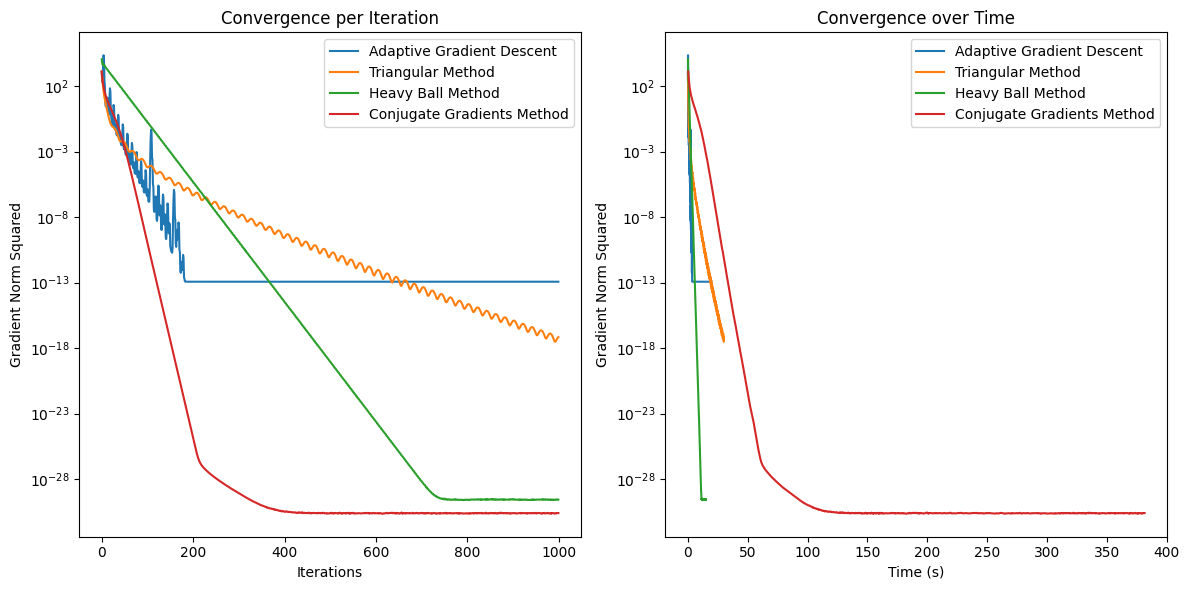

In [53]:
lin_reg = LinearRegression('data/task1/X.npy', 'data/task1/y.npy')

w_0 = np.ones(lin_reg.n)
num_iter = 1000
L = 4.010854812764679
alpha_0 = 0.0
A_0 = 0.0
beta = 0.9

lin_reg.adaptive_gradient_descent(w_0, L, num_iter)
lin_reg.triangular_method(w_0, alpha_0, A_0, L, num_iter)
lin_reg.heavy_ball_method(w_0, beta, L, num_iter)
lin_reg.conjugate_gradients_method(w_0, L, num_iter)

lin_reg.visualize_convergence_comparison()


На практике методы оптимизации подтвердили теоретические ожидания. Ускоренные методы, такие как тяжелый шарик и метод треугольников, показали высокую эффективность, где тяжелый шарик быстрее сходится к оптимуму, а метод треугольников демонстрирует стабильную, но более медленную сходимость. Адаптивный градиентный спуск наиболее быстро достигает своей точности благодаря агрессивной настройке шага, но уступает ускоренным методам в конечной точности. Метод сопряженных градиентов обеспечивает наилучшую сходимость по числу итераций, однако требует больше времени на шаг из-за необходимости решения вспомогательной задачи минимизации, что замедляет общую работу.

## Задача 2. Логистическая регрессия [11]

Рассмотрим задачу логистической регрессии:

$$\min_{w\in\mathbb{R}^n} \frac{1}{m} \sum\limits_{i=1}^m \log\left(1+\exp(-y_i \langle w, x_i\rangle)\right) + \frac{\alpha}{2}\|w\|_2^2,$$
где $\{x_i, y_i\}_{i=1}^m \in \mathbb{R}^n\times \{-1,1\}$ есть обучающая выборка, $\alpha\in\mathbb{R}_+$ - некоторый параметр $\ell_2$-регуляризации. Параметр $\alpha=0.01$ в этой задаче, матрицы $X,y$ загрузите из файлов `data/task2/X.npy` и `data/task2/y.npy.`

В этом задании мы сравним различные методы для решения этой задачи.

0. [1] Реализуйте вычисление целевой функции и её градиента. Проверьте, что ваши реализации являются устойчивыми и дают адекватный результат при больших значениях $|y_i \langle w, x_i\rangle|$.


1. [1] Чему равна константа сильной выпуклости $\mu$ исходной задачи?

1. [3] Реализуйте метод Флетчера-Ривса и Полака–Райбьера–Поляка (см. Лекция 5)

2. [3] Подберите лучшие значения для неизвестных параметров этих методов, а также методов из пункта 3 предыдущей задачи

3. [3] Проведите сравнение методов Флетчера-Ривса и Полака–Райбьера–Поляка с методами из Задачи 1

### Решение задачи 2:

In [56]:
class LogisticRegression(LinearRegression):
    def __init__(self, X_path, y_path, lambda_reg=0.01):
        super().__init__(X_path, y_path, lambda_reg)
        

    def loss_function(self, w):
        return np.mean(np.log(1 + np.exp(- self.y.T @ (self.X @ w)))) + 1 / 2 * self.lambda_reg * np.linalg.norm(w) ** 2

    def loss_gradient(self, w):
        sigm = 1 / (1 + np.exp(- self.y.T @ (self.X @ w)))
        return - 1 / self.m * self.X.T @ (self.y * (1 - sigm)) + self.lambda_reg * w


    # sorry, i don't wanna solve 1-dim minimization problem,
    # hope, you will understand
    def minimize_1_dim(self, w, p):
        def f(a):
            return self.loss_function(w + a * p)
        return minimize_scalar(f).x

    def polyak_ribiere(self, w_0, num_iter):
        self.reset_history()
        w = w_0.copy()
        p = np.zeros_like(w)
        grad = self.loss_gradient(w)

        start_time = time()
        for i in tqdm(range(num_iter), desc='Polak-Ribiere-Polyak'):
            grad_prev = grad.copy()
            grad = self.loss_gradient(w)
            beta = grad.T @ (grad - grad_prev) / (np.linalg.norm(grad_prev) ** 2)
            p = - grad + beta * p        
            alpha = self.minimize_1_dim(w, p)
            w += alpha * p
            grad = self.loss_gradient(w)

            self.save_iteration_results(i + 1, grad, time() - start_time)
        
        self.histories['Polak-Ribiere-Polyak'] = self.history

    
    def fletcher_rives(self, w_0, num_iter):
        self.reset_history()
        w = w_0.copy()
        p = np.zeros_like(w)
        grad = self.loss_gradient(w)

        start_time = time()
        for i in tqdm(range(num_iter), desc='Fletcher-Rives'):
            grad_norm_prev = np.linalg.norm(grad) ** 2
            grad_norm = np.linalg.norm(self.loss_gradient(w)) ** 2
            beta = grad_norm / grad_norm_prev
            p = - grad + beta * p
            alpha = self.minimize_1_dim(w, p)
            w += alpha * p

            grad = self.loss_gradient(w)
            self.save_iteration_results(i + 1, grad, time() - start_time)

        self.histories['Fletcher-Rives'] = self.history


/var/folders/5g/qvrkwr6j5lz483p8_wp_vp2m0000gn/T/ipykernel_81274/1637623391.py:10: RuntimeWarning: overflow encountered in exp
  sigm = 1 / (1 + np.exp(- self.y.T @ (self.X @ w)))
/var/folders/5g/qvrkwr6j5lz483p8_wp_vp2m0000gn/T/ipykernel_81274/1637623391.py:7: RuntimeWarning: overflow encountered in exp
  return np.mean(np.log(1 + np.exp(- self.y.T @ (self.X @ w)))) + 1 / 2 * self.lambda_reg * np.linalg.norm(w) ** 2
Fletcher-Rives:   0%|          | 0/1000 [00:00<?, ?it/s]/Users/macbook/egor123/Optimization_course/opt-venv/lib/python3.12/site-packages/scipy/optimize/_optimize.py:2472: RuntimeWarning: invalid value encountered in scalar multiply
  tmp2 = (x - v) * (fx - fw)
Polak-Ribiere-Polyak: 100%|██████████| 1000/1000 [01:08<00:00, 14.61it/s]


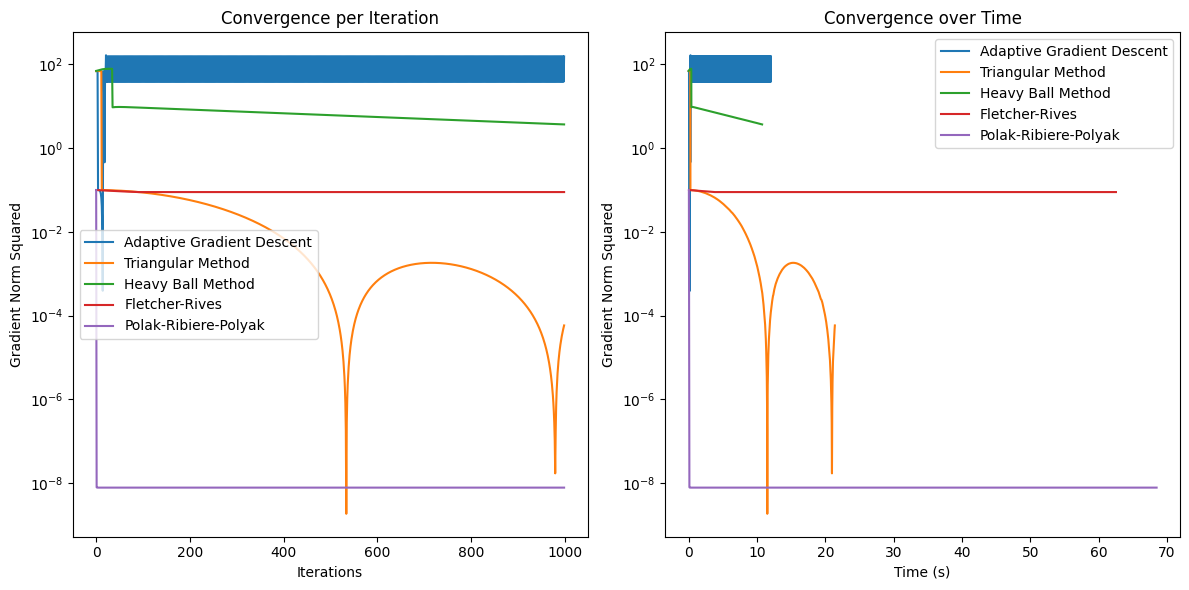

In [59]:
log_reg = LogisticRegression('data/task2/X.npy', 'data/task2/y.npy')

w_0 = np.ones(log_reg.n)
num_iter = 1000
L = 196.9104936068204
alpha_0 = 0.0
A_0 = 0.0
beta = 0.9

log_reg.adaptive_gradient_descent(w_0, L, num_iter)
log_reg.triangular_method(w_0, alpha_0, A_0, L, num_iter)
log_reg.heavy_ball_method(w_0, beta, L, num_iter)
log_reg.fletcher_rives(w_0, num_iter)
log_reg.polyak_ribiere(w_0, num_iter)


log_reg.visualize_convergence_comparison()

На практике методы Флетчера–Ривса и Полака–Райбьера–Поляка подтвердили свою эффективность, аналогично методу сопряженных градиентов. Эти методы демонстрируют стабильную и быструю сходимость по числу итераций, значительно превосходя базовые методы, такие как адаптивный градиентный спуск, метод треугольников и тяжелый шарик. Однако их применение связано с повышенными вычислительными затратами, так как на каждом шаге необходимо решать дополнительную задачу оптимизации.